# Radiant Descent: Milestone 1

**Team Radiant Descent:** Aunonto Rahman, Michael Dai, Syed Masrur Ahmed

An action-conditioned diffusion world model of Atari Space Invaders. Given the last K = 4 frames
and the actions taken at them, the model generates the next frame. Milestone 1 compares one
baseline, **copy-last-frame** (0 parameters), with one simple model, the **`small` EDM U-Net**
(14,263,683 parameters), on the same held-out windows.

## 1. Setup

In [1]:
import os
from pathlib import Path

# Run from the repo root wherever the notebook was opened (the root holds ROADMAP.md).
root = Path.cwd().resolve()
while not (root / "ROADMAP.md").exists():
    if root.parent == root:
        raise RuntimeError("Could not find the repo root (no ROADMAP.md above this notebook).")
    root = root.parent
os.chdir(root)

import json
import sys
import tempfile
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from IPython.display import Image, Markdown, display

sys.path.insert(0, str(root / "scripts"))  # eval_single_step.py is the evaluation used for the saved results
from eval_single_step import pick_indices, run as run_eval  # noqa: E402
import memorize  # noqa: E402  (scripts/memorize.py)

from wm.config import load_config
from wm.data.dataset import WindowDataset, is_val_episode
from wm.data.reader import ShardReader, list_shards
from wm.data.schema import ACTION_MEANINGS, SOURCE_AGENT, SOURCE_HUMAN, SOURCE_RANDOM
from wm.eval.baselines import CopyLastFrame
from wm.eval.visualize import save_grid
from wm.inference import WorldModel

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

RUN_EVAL = True  # False: show the saved results in results/milestone1/ (no data or checkpoint needed)
N = 64           # val windows; the saved results use 64
MEMORIZE = RUN_EVAL and device.type != "cpu"  # section 6 fine-tunes for ~3 min on MPS/GPU (15-30 min on CPU)

RUN_DIR = Path("runs/20261105-0558_debug_small")
CKPT = RUN_DIR / "checkpoints/ckpt_last.pt"
DATA_DIR = Path("data/debug")
EVAL_CONFIG = Path("configs/eval/single_step.yaml")
RESULTS = Path("results/milestone1")
MODELS = {"copy_last": "copy_last", "small U-Net": str(CKPT)}  # name -> eval spec
TAGS = {"copy_last": "copy_last", "small U-Net": "20261105-0558_debug_small_ckpt_last"}  # results folders

torch.set_grad_enabled(False)
warnings.filterwarnings("ignore", category=UserWarning, module="torchvision")  # lpips's AlexNet loading
print(f"repo root: {root.name}/\ndevice: {device}\nRUN_EVAL={RUN_EVAL}, N={N}")

repo root: Diffusion-Space-Invaders/
device: mps
RUN_EVAL=True, N=64


In [2]:
missing = [str(p) for p in (CKPT, DATA_DIR) if not p.exists()]
if RUN_EVAL and missing:
    raise FileNotFoundError(
        f"RUN_EVAL=True needs {', '.join(missing)}. See the 'Milestone 1' section of README.md for "
        "the checkpoint and data downloads, or set RUN_EVAL = False to show the saved results.")
HAVE_DATA = DATA_DIR.exists()
HAVE_CKPT = CKPT.exists()
print(f"data: {'found' if HAVE_DATA else 'missing'}, checkpoint: {'found' if HAVE_CKPT else 'missing'}")

data: found, checkpoint: found


## 2. Data

`data/debug/` holds gameplay collected with a mix of a trained agent and random actions, stored as
HDF5 shards of 84×84 RGB frames (max-pooled over the frame skip to remove flicker). A training sample
is a window: K = 4 context frames, the 4 actions taken at them, and the next frame as the target. The
train/val split is **by episode** (a hash of shard name and episode id), so no validation episode is
seen in training.

In [3]:
eval_cfg = load_config(EVAL_CONFIG)
K, VAL_FRACTION = int(eval_cfg["data"]["K"]), float(eval_cfg["data"]["val_fraction"])

if HAVE_DATA:
    rows, lengths, sources, n_split = 0, [], [], {"train": 0, "val": 0}
    for path in list_shards(DATA_DIR):
        reader = ShardReader(path)
        eps = reader.episodes
        rows += reader.num_rows
        lengths += eps["length"].tolist()
        sources += eps["source"].tolist()
        for uid, length in zip(eps["episode_uid"], eps["length"]):
            if length > K:  # episodes with at least one window
                n_split["val" if is_val_episode(path.name, int(uid), VAL_FRACTION) else "train"] += 1
        reader.close()
    sources = np.array(sources)
    names = {SOURCE_AGENT: "agent", SOURCE_RANDOM: "random", SOURCE_HUMAN: "human"}
    datasets = {split: WindowDataset([DATA_DIR], K, split, val_fraction=VAL_FRACTION) for split in ("train", "val")}
    display(Markdown("\n".join([
        "| | |", "|---|---|",
        f"| shards | {len(list_shards(DATA_DIR))} |",
        f"| frames (rows) | {rows:,} |",
        f"| episodes | {len(lengths):,} (" + ", ".join(f"{names[s]} {int((sources == s).sum()):,}"
                                               for s in names if (sources == s).any()) + ") |",
        f"| mean episode length | {np.mean(lengths):,.0f} frames |",
        f"| train | {len(datasets['train']):,} windows from {n_split['train']:,} episodes |",
        f"| val | {len(datasets['val']):,} windows from {n_split['val']:,} episodes |",
    ])))
else:
    print("data/debug/ not found: skipping the dataset statistics.")

| | |
|---|---|
| shards | 12 |
| frames (rows) | 500,688 |
| episodes | 688 (agent 457, random 231) |
| mean episode length | 728 frames |
| train | 471,846 windows from 654 episodes |
| val | 26,090 windows from 34 episodes |

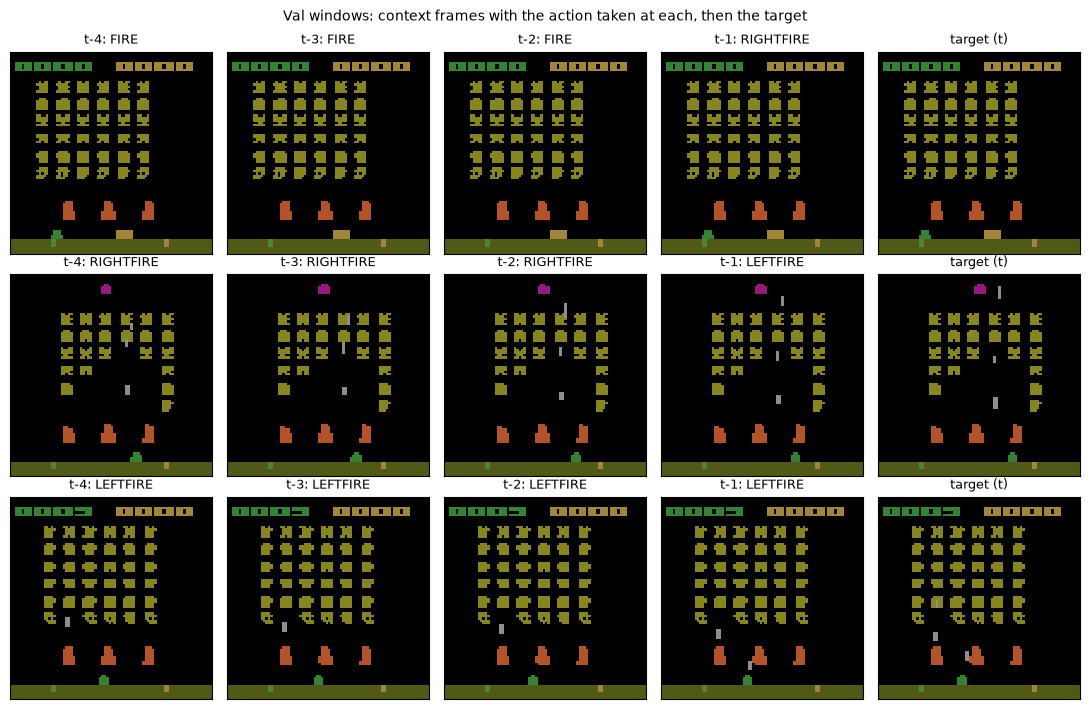

In [4]:
def show_windows(dataset, indices, scale=4):
    """Context frames and target for a few windows; titles are the action taken at each frame."""
    fig, axes = plt.subplots(len(indices), K + 1, figsize=(2.2 * (K + 1), 2.4 * len(indices)))
    for r, idx in enumerate(indices):
        item = dataset[int(idx)]
        frames = list(item["context"]) + [item["target"]]
        for c, frame in enumerate(frames):
            img = ((frame.permute(1, 2, 0) + 1) * 127.5).round().clamp(0, 255).to(torch.uint8).numpy()
            img = img.repeat(scale, 0).repeat(scale, 1)  # nearest-neighbour upscaling, no aspect correction
            ax = axes[r, c]
            ax.imshow(img, interpolation="nearest")
            ax.set_xticks([]), ax.set_yticks([])
            ax.set_title(f"t-{K - c}: {ACTION_MEANINGS[int(item['actions'][c])]}" if c < K else "target (t)",
                         fontsize=9)
    fig.suptitle("Val windows: context frames with the action taken at each, then the target", fontsize=10)
    fig.tight_layout()
    plt.show()


if HAVE_DATA:
    show_windows(datasets["val"], pick_indices(len(datasets["val"]), 3))
    for ds in datasets.values():
        ds.close()

Frames from the CP1 environment check (raw emulator frame vs the model's 84×84 max-pooled frame):

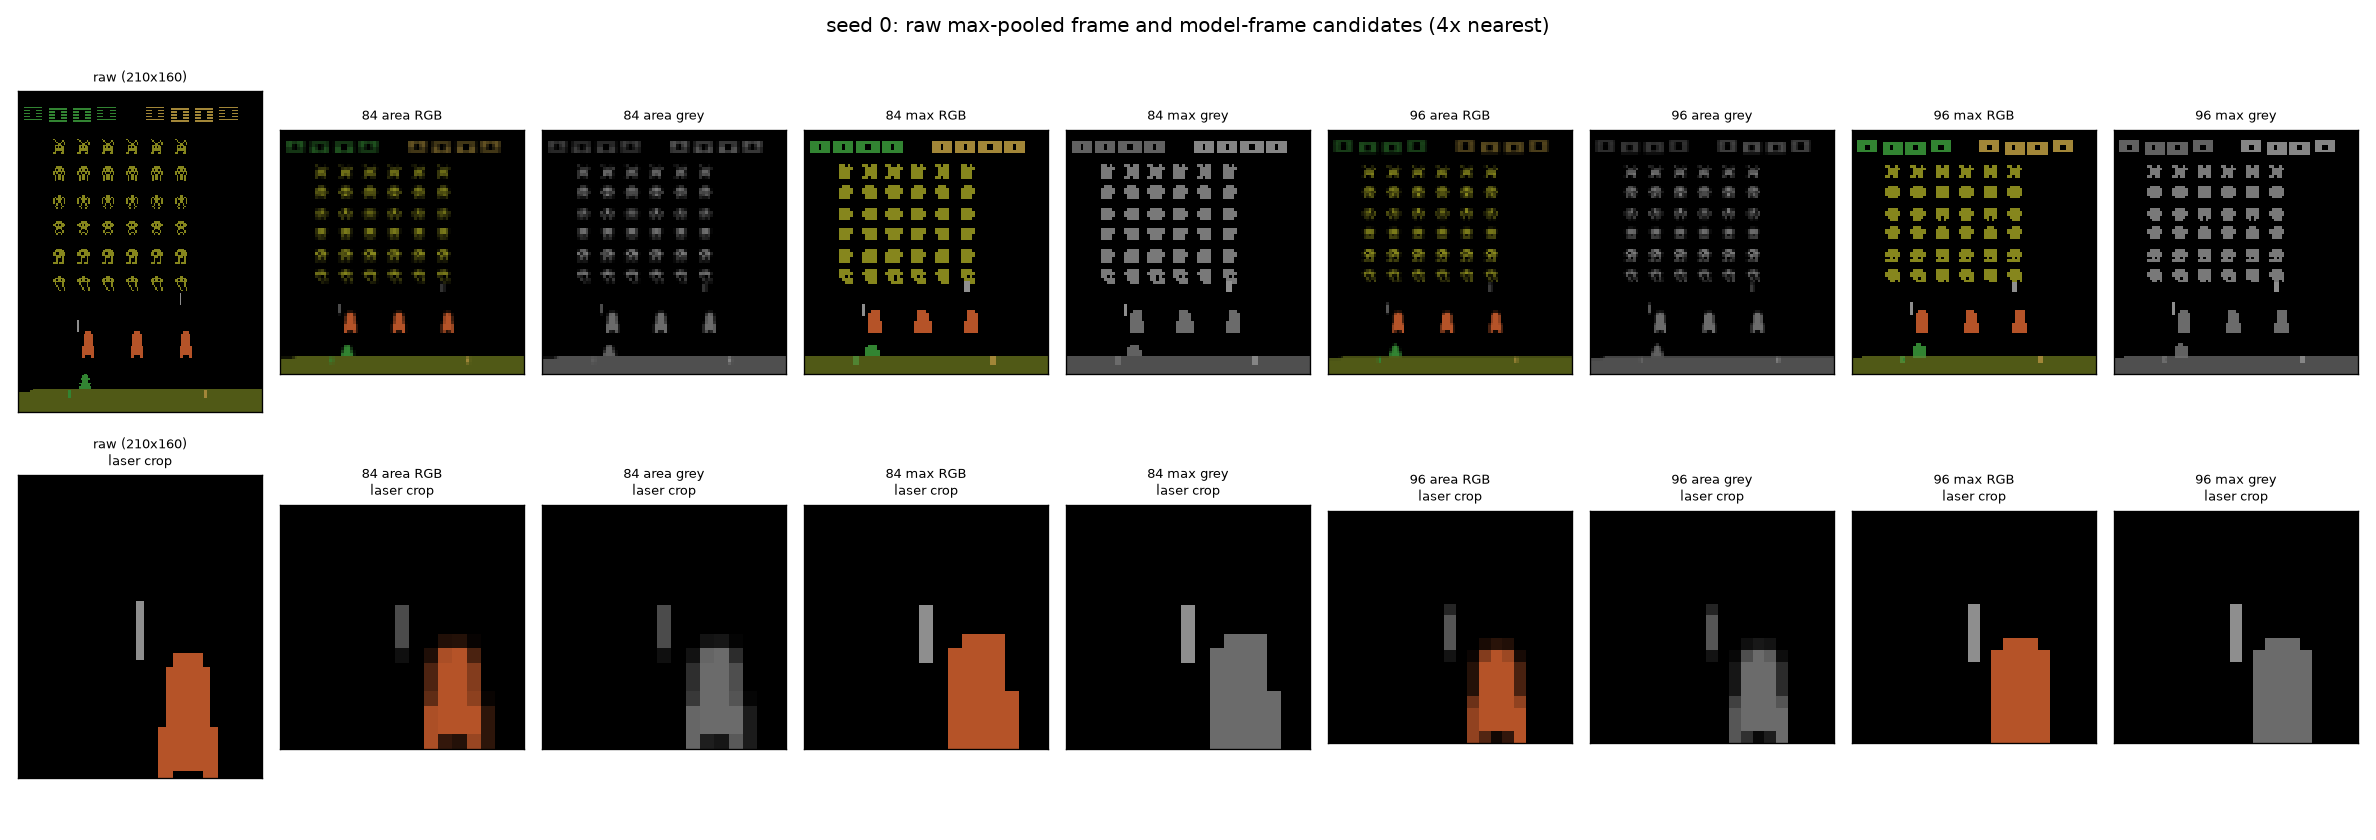

In [5]:
display(Image(filename="docs/figures/cp1_frames.png", width=700))

## 3. Models

- **Copy-last-frame**: predicts that the next frame equals the last context frame. 0 parameters.
- **`small` EDM U-Net**: a denoiser trained with the EDM diffusion objective. Input: the noisy next
  frame concatenated with the 4 context frames; actions and the noise level enter through adaptive
  group norm. Sampling: 3 Euler steps on a Karras schedule, with the EMA weights.

In [6]:
copy_last = CopyLastFrame(K, 3, 84, 84)
n_copy = sum(p.numel() for p in getattr(copy_last, "parameters", lambda: [])())
print(f"copy_last: {n_copy:,} parameters")

if HAVE_CKPT:
    ckpt = torch.load(CKPT, map_location="cpu", weights_only=False)
    run_cfg, step = ckpt["config"], ckpt["step"]
    del ckpt
    model = WorldModel.from_checkpoint(CKPT, device=device, use_ema=True)
    n_unet = sum(p.numel() for p in model.denoiser.parameters())
    print(f"small U-Net: {n_unet:,} parameters (EMA weights, step {step:,}, on {device})")
else:
    from wm.train.trainer import ModelSection, build_net

    run_cfg = yaml.safe_load((RESULTS / "run/config.yaml").read_text())
    n_unet = sum(p.numel() for p in build_net(ModelSection(**run_cfg["model"]), 3, K, 84).parameters())
    print(f"small U-Net: {n_unet:,} parameters (checkpoint not found: built from results/milestone1/run/config.yaml)")

m, t, s, e = run_cfg["model"], run_cfg["train"], run_cfg["sampler"], run_cfg["edm"]
display(Markdown("\n".join([
    "| hyperparameter | value |", "|---|---|",
    f"| U-Net channels, res blocks, embedding | {m['ch']}, {m['n_res']} per level, {m['emb_dim']} |",
    f"| context K, batch size | {run_cfg['data']['K']}, {run_cfg['data']['batch_size']} |",
    f"| steps, lr, warmup | {t['steps']:,}, {t['lr']}, {t['warmup_steps']:,} |",
    f"| AdamW betas, weight decay, grad clip | {t['betas']}, {t['weight_decay']}, {t['grad_clip']} |",
    f"| EMA decay, action dropout | {t['ema_decay']}, {t['p_action_drop']} |",
    f"| EDM σ_data, P_mean, P_std | {e['sigma_data']}, {e['p_mean']}, {e['p_std']} |",
    f"| sampler | {s['method']}, {s['num_steps']} steps, σ ∈ [{s['sigma_min']}, {s['sigma_max']}], ρ = {s['rho']} |",
])))

copy_last: 0 parameters


UNet: 14,263,683 parameters
small U-Net: 14,263,683 parameters (EMA weights, step 20,000, on mps)


| hyperparameter | value |
|---|---|
| U-Net channels, res blocks, embedding | [64, 128, 256], 2 per level, 256 |
| context K, batch size | 4, 64 |
| steps, lr, warmup | 20,000, 0.0001, 1,000 |
| AdamW betas, weight decay, grad clip | [0.9, 0.999], 0.01, 1.0 |
| EMA decay, action dropout | 0.999, 0.1 |
| EDM σ_data, P_mean, P_std | 0.5, -0.4, 1.2 |
| sampler | euler, 3 steps, σ ∈ [0.002, 5.0], ρ = 7.0 |

## 4. Evaluation

Teacher-forced single-step prediction on the val split: each model predicts the target from the real
context. Both models see exactly the same windows (`N` evenly spaced val windows) and the same
sampler seed, using `run` from `scripts/eval_single_step.py`, the script that produced the saved
results. Frames are mapped to [0,1]; PSNR is capped at 100 dB for identical frames. Values are
mean ± 95% CI over windows.

In [7]:
saved = {name: json.loads((RESULTS / "eval" / tag / "metrics.json").read_text()) for name, tag in TAGS.items()}

if RUN_EVAL:
    results, grids = {}, {}
    for name, spec in MODELS.items():
        results[name], grids[name] = run_eval(spec, eval_cfg, N, device)
        print(f"{name}: {results[name]['seconds']:.0f} s on {device}")
else:
    results = saved
    print("RUN_EVAL=False: showing the saved results from results/milestone1/eval/")

rows = ["| model | parameters | PSNR (dB) ↑ | SSIM ↑ | LPIPS ↓ |", "|---|---|---|---|---|"]
params = {"copy_last": n_copy, "small U-Net": n_unet}
for name, res in results.items():
    mt = res["metrics"]
    rows.append(f"| {name} | {params[name]:,} | " + " | ".join(
        f"{mt[k]['mean']:.{d}f} ± {mt[k]['ci95']:.{d}f}" for k, d in (("psnr", 2), ("ssim", 4), ("lpips", 4))) + " |")
n_eval = next(iter(results.values()))["n"]
capped = results["copy_last"]["metrics"]["psnr"]["capped_fraction"]
display(Markdown("\n".join(rows) + f"\n\n{n_eval} val windows of {next(iter(results.values()))['val_windows']:,}; "
                 f"{capped:.1%} of copy-last's windows are identical frames at the 100 dB PSNR cap."))

copy_last: 6 s on mps
UNet: 14,263,683 parameters


small U-Net: 8 s on mps


| model | parameters | PSNR (dB) ↑ | SSIM ↑ | LPIPS ↓ |
|---|---|---|---|---|
| copy_last | 0 | 34.29 ± 4.33 | 0.9636 ± 0.0080 | 0.0122 ± 0.0030 |
| small U-Net | 14,263,683 | 33.84 ± 1.13 | 0.7401 ± 0.0145 | 0.0081 ± 0.0026 |

64 val windows of 26,090; 6.2% of copy-last's windows are identical frames at the 100 dB PSNR cap.

In [8]:
# The fresh numbers must match the saved metrics.json (relative tolerance 1e-3).
if RUN_EVAL and N == saved["copy_last"]["n"]:
    for name in MODELS:
        for metric, ref in saved[name]["metrics"].items():
            for key in ("mean", "ci95"):
                got, want = results[name]["metrics"][metric][key], ref[key]
                assert abs(got - want) <= 1e-3 * abs(want), f"{name} {metric} {key}: {got} vs saved {want}"
    print("Fresh results match the saved metrics.json (rel. tol. 1e-3).")
elif RUN_EVAL:
    print(f"N={N} differs from the saved results (n={saved['copy_last']['n']}): not compared.")

Fresh results match the saved metrics.json (rel. tol. 1e-3).


## 5. Qualitative results

**copy_last**

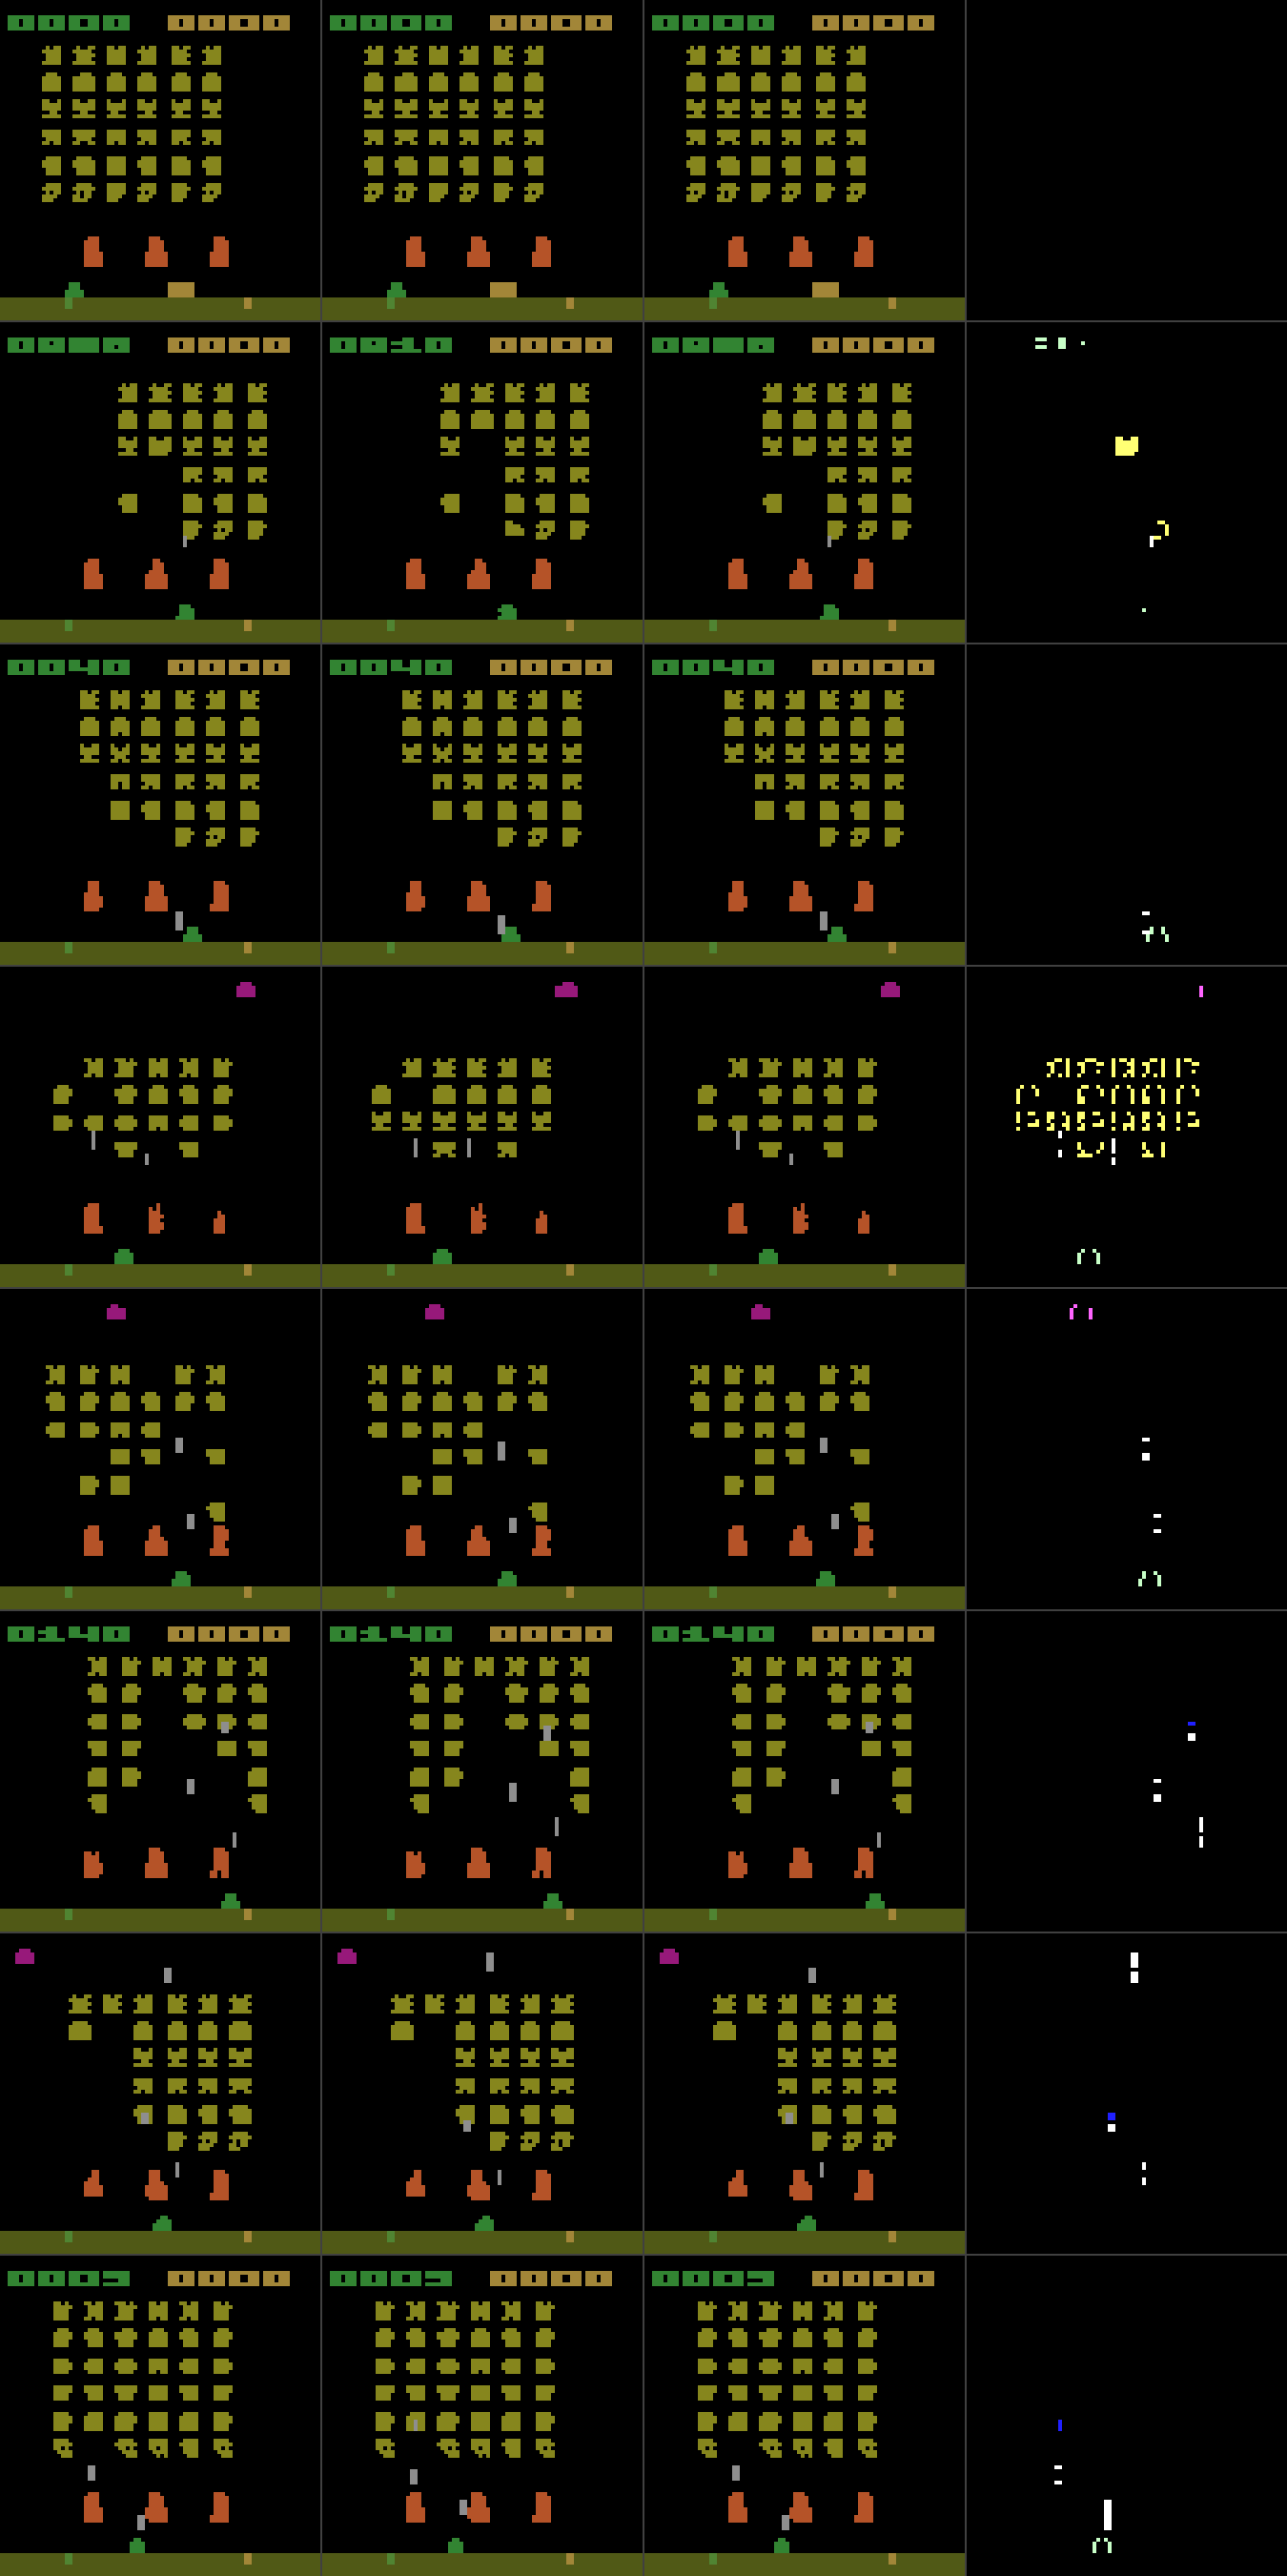

**small U-Net**

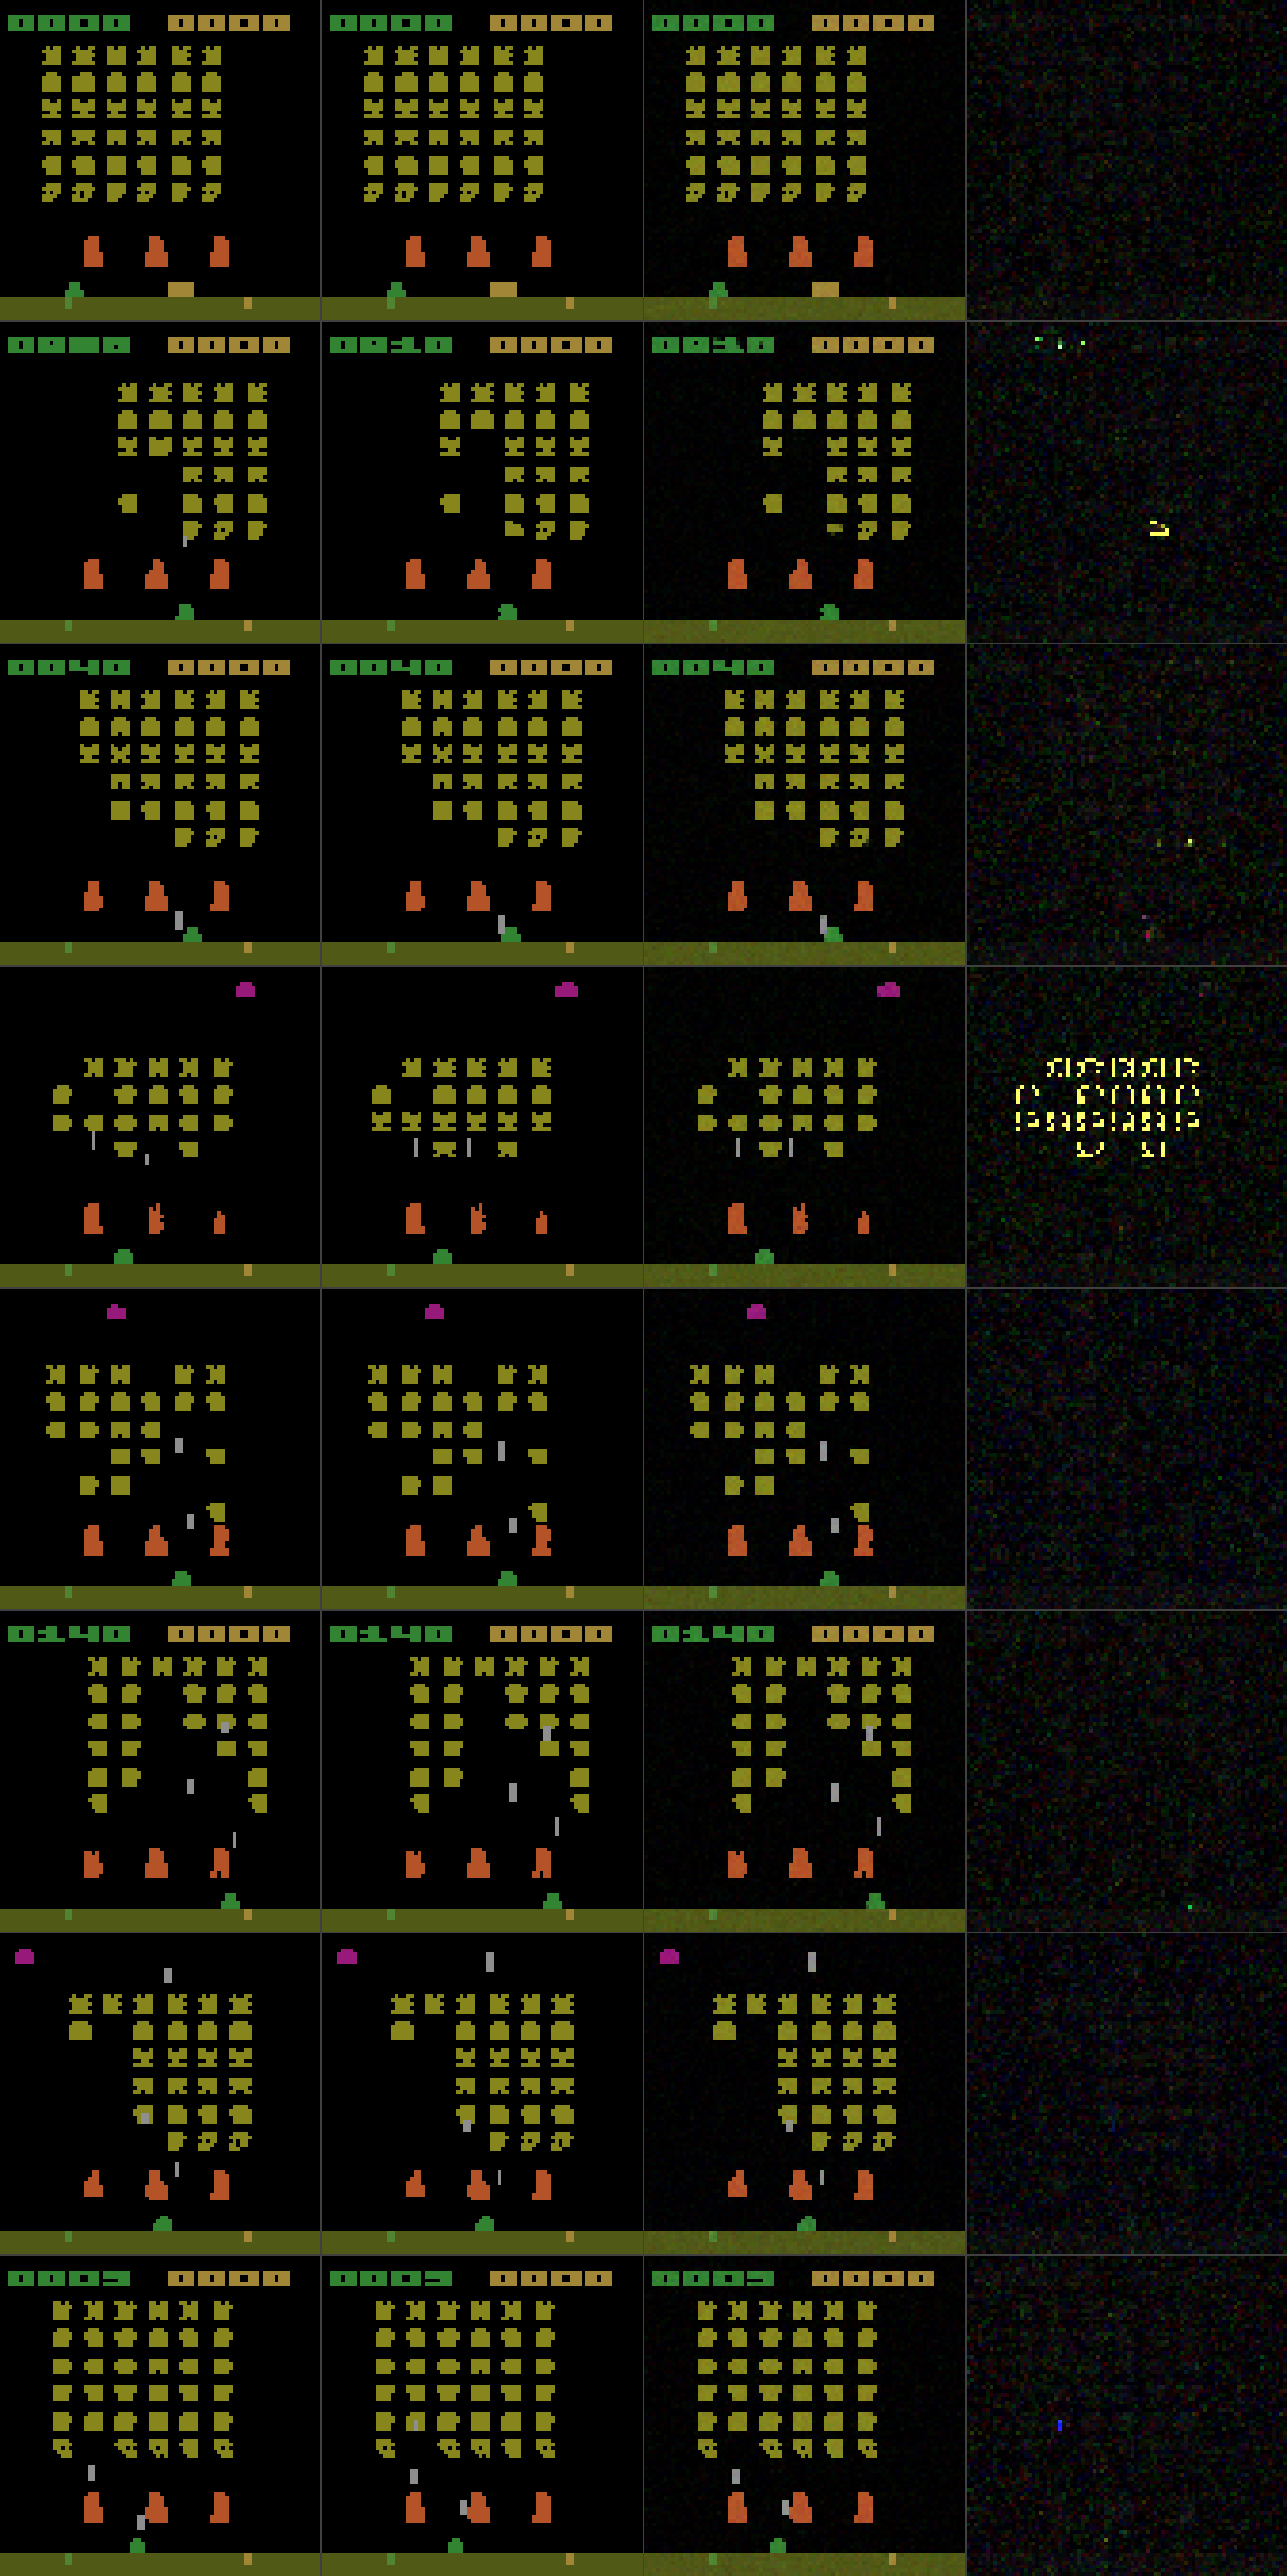

In [9]:
grid_dir = Path(tempfile.mkdtemp())
for name, tag in TAGS.items():
    if RUN_EVAL:
        path = grid_dir / f"{tag}.png"
        save_grid(path, grids[name]["context"], grids[name]["target"], grids[name]["pred"])
    else:
        path = RESULTS / "eval" / tag / "grid.png"
    display(Markdown(f"**{name}**"))
    display(Image(filename=str(path), width=520))

Each row is one val window. Columns: **last context frame | target | prediction | |target −
prediction| × 4**. Copy-last is exactly right when nothing moves and wrong wherever something does.
The U-Net places bullets, the player, and the shifted formation correctly, but leaves faint speckle
on the black background: with only 3 Euler sampling steps a little residual noise survives, which
costs it little PSNR but a lot of SSIM (SSIM is very sensitive to noise on flat regions). When the
alien formation's pose (its two-frame march animation) is wrong, that is mostly hidden emulator
timing: the frames do not show when the next march step happens, so no model can know it from the
context alone.

## 6. Memorization check

Can the model fit examples it has seen? We fine-tune the trained U-Net (starting from its EMA
weights) on one batch of 20 evenly spaced **training** windows for 150 steps (AdamW, lr 1e-4, no
action dropout), then score it on **the same 20 windows**, alongside copy-last and the checkpoint
before fine-tuning. This uses `scripts/memorize.py`, which scores with the same `evaluate` as
section 4. With `MEMORIZE = False` (the default on CPU, where it takes 15 to 30 minutes) the
saved results from `results/milestone1/memorize/` are shown. GPU training is not bit-reproducible,
so a fresh run gives close but not identical numbers.

UNet: 14,263,683 parameters


fine-tuned 150 steps in 172 s on mps


| 20 train windows | PSNR (dB) ↑ | SSIM ↑ | LPIPS ↓ |
|---|---|---|---|
| copy_last | 33.78 ± 6.99 | 0.9699 ± 0.0146 | 0.0114 ± 0.0062 |
| U-Net before fine-tuning | 33.28 ± 2.18 | 0.7568 ± 0.0260 | 0.0094 ± 0.0068 |
| U-Net after fine-tuning | 36.94 ± 0.41 | 0.7798 ± 0.0217 | 0.0027 ± 0.0020 |

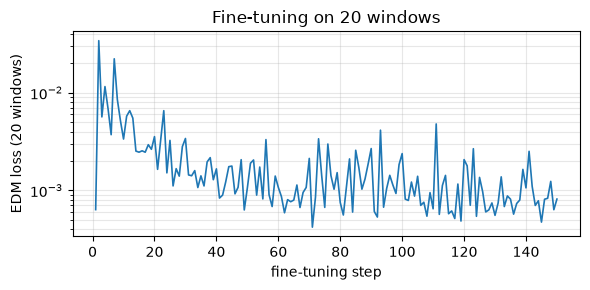

**After fine-tuning** (8 of the 20 windows; same columns as section 5)

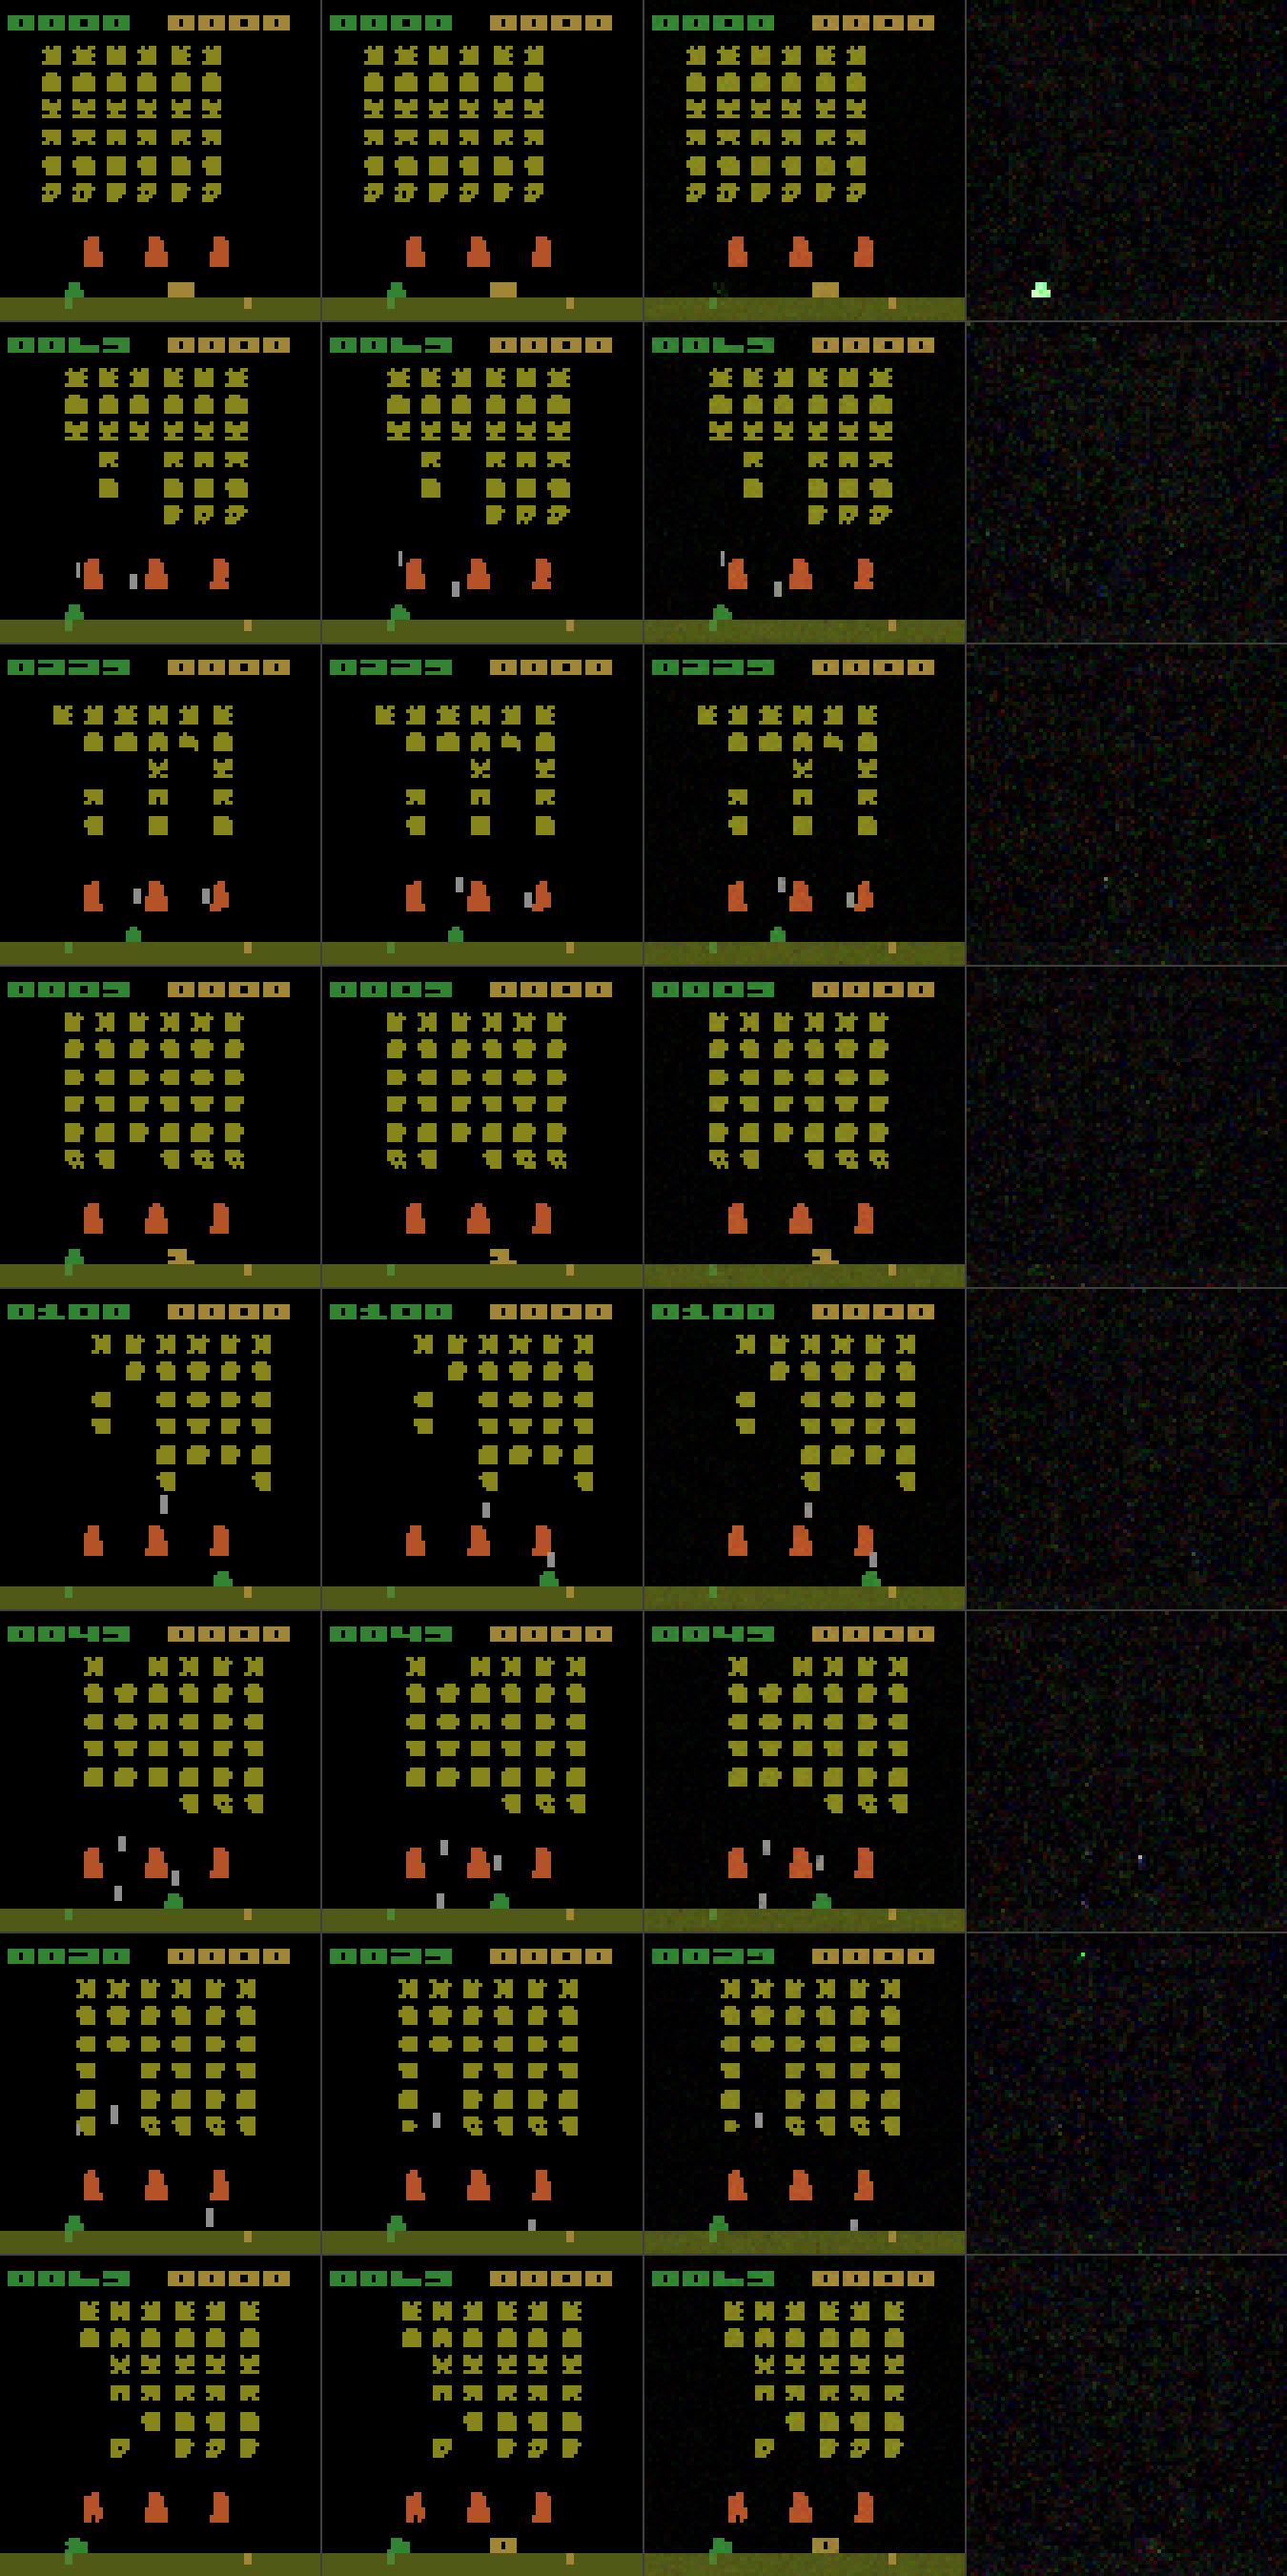

In [10]:
MEM_DIR = RESULTS / "memorize"
if MEMORIZE:
    mem = memorize.run(str(CKPT), eval_cfg, n=20, steps=150, lr=1e-4, device=device)
    mem_grid = grid_dir / "memorize.png"
    save_grid(mem_grid, mem["grid"]["context"], mem["grid"]["target"], mem["grid"]["pred"])
    print(f"fine-tuned {mem['steps']} steps in {mem['seconds']:.0f} s on {device}")
else:
    mem = json.loads((MEM_DIR / "metrics.json").read_text())
    mem_grid = MEM_DIR / "grid.png"
    print(f"MEMORIZE=False: showing the saved run ({mem['steps']} steps on {mem['device']})")

labels = {"copy_last": "copy_last", "before": "U-Net before fine-tuning", "after": "U-Net after fine-tuning"}
rows = ["| 20 train windows | PSNR (dB) ↑ | SSIM ↑ | LPIPS ↓ |", "|---|---|---|---|"]
for key, label in labels.items():
    mt = mem["metrics"][key]
    rows.append(f"| {label} | " + " | ".join(
        f"{mt[k]['mean']:.{d}f} ± {mt[k]['ci95']:.{d}f}" for k, d in (("psnr", 2), ("ssim", 4), ("lpips", 4))) + " |")
display(Markdown("\n".join(rows)))

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(1, len(mem["losses"]) + 1), mem["losses"], lw=1.2)
ax.set(xlabel="fine-tuning step", ylabel="EDM loss (20 windows)", yscale="log", title="Fine-tuning on 20 windows")
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()
display(Markdown("**After fine-tuning** (8 of the 20 windows; same columns as section 5)"))
display(Image(filename=str(mem_grid), width=520))

The fine-tuned model reproduces almost everything in the windows it was trained on: the
remaining error is mostly the faint background speckle, so LPIPS and PSNR improve a lot while SSIM
barely moves. That points to the 3-step sampler, not too little training, as the main cause of the
low SSIM in section 4.

## 7. Training curve

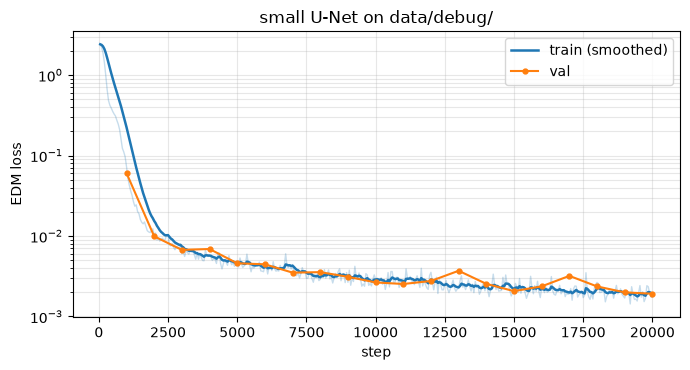

20,000 steps; final train loss 0.0017 (smoothed 0.0019), final val loss 0.0019; median throughput 292 samples/s


In [11]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

acc = EventAccumulator(str(RESULTS / "run/tb"))
acc.Reload()
train = np.array([(e.step, e.value) for e in acc.Scalars("train/loss")])
val = np.array([(e.step, e.value) for e in acc.Scalars("val/loss")])
sps = np.array([e.value for e in acc.Scalars("train/samples_per_s")])

smooth = np.copy(train[:, 1])  # light exponential smoothing of the train loss
for i in range(1, len(smooth)):
    smooth[i] = 0.8 * smooth[i - 1] + 0.2 * train[i, 1]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(train[:, 0], train[:, 1], color="tab:blue", alpha=0.25, lw=1)
ax.plot(train[:, 0], smooth, color="tab:blue", lw=1.8, label="train (smoothed)")
ax.plot(val[:, 0], val[:, 1], "o-", color="tab:orange", ms=3.5, lw=1.5, label="val")
ax.set(xlabel="step", ylabel="EDM loss", yscale="log", title="small U-Net on data/debug/")
ax.grid(alpha=0.3, which="both")
ax.legend()
fig.tight_layout()
plt.show()
print(f"{int(train[-1, 0]):,} steps; final train loss {train[-1, 1]:.4f} (smoothed {smooth[-1]:.4f}), "
      f"final val loss {val[-1, 1]:.4f}; median throughput {np.median(sps):.0f} samples/s")

## 8. Conclusion

On 64 held-out validation windows, the small U-Net beats copy-last on LPIPS (0.0081 vs 0.0122) and
roughly ties on PSNR (33.84 vs 34.29 dB, with overlapping confidence intervals). It is clearly worse
on SSIM (0.740 vs 0.964). The grids show that the model correctly places the moving parts copy-last
misses: bullets, the player, and the shifted alien formation. It leaves faint speckle on the black
background. The speckle is residual noise from sampling with only 3 Euler steps. SSIM is very
sensitive to noise on flat regions, so it penalizes this far more than PSNR or LPIPS do. Next we
will try more sampling steps and longer training (20k of a planned 50k steps). For the next
milestone we will roll the model out autoregressively over many frames and add context-noise
augmentation to limit drift.